In [1]:

import os
import re
import random
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)
print("Libraries imported successfully.")


TensorFlow version: 2.20.0
GPU available: False
Libraries imported successfully.


2026-10-14 11:22:44.055746: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [2]:

input_dir = Path("/kaggle/input")
csv_files = list(input_dir.rglob("*.csv")) if input_dir.exists() else []

# Also check the notebook working directory.
csv_files += [
    path for path in Path("/kaggle/working").glob("*.csv")
    if path not in csv_files
]

def normalize_filename(path):
    return re.sub(r"[_-]+", " ", path.stem.casefold()).strip()

matches = [
    path for path in csv_files
    if "language detection" in normalize_filename(path)
]

if matches:
    CSV_PATH = str(matches[0])
elif len(csv_files) == 1:
    CSV_PATH = str(csv_files[0])
else:
    print("CSV files found:")
    for path in csv_files:
        print(path)
    raise FileNotFoundError(
        "Could not identify Language Detection.csv. "
        "Attach the dataset or set CSV_PATH manually."
    )

print("Dataset path:", CSV_PATH)

df = pd.read_csv(CSV_PATH)

# Remove accidental spaces from column names.
df.columns = df.columns.astype(str).str.strip()

print("\nFirst five rows:")
display(df.head())

print("\nDataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())


Dataset path: /kaggle/input/datasets/zarajamshaid/language-identification-datasst/dataset.csv

First five rows:


,Text,language
0,klement gottwaldi surnukeha palsameeriti ning ...,Estonian
1,sebes joseph pereira thomas på eng the jesuit...,Swedish
2,ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...,Thai
3,விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...,Tamil
4,de spons behoort tot het geslacht haliclona en...,Dutch



Dataset shape: (22000, 2)

Columns: ['Text', 'language']


In [3]:

# Identify the text and target columns, ignoring capitalization.
column_lookup = {
    str(column).strip().casefold(): column
    for column in df.columns
}

if "text" not in column_lookup or "language" not in column_lookup:
    raise ValueError(
        "Required columns 'Text' and 'language' were not found. "
        f"Available columns: {df.columns.tolist()}"
    )

df = df.rename(columns={
    column_lookup["text"]: "Text",
    column_lookup["language"]: "language"
})

# Keep only the columns needed for this project.
df = df[["Text", "language"]].copy()

# Remove missing or empty values.
df = df.dropna(subset=["Text", "language"]).copy()

df["Text"] = df["Text"].astype(str).str.strip()
df["language"] = df["language"].astype(str).str.strip()

df = df[
    (df["Text"] != "") &
    (df["language"] != "")
].reset_index(drop=True)

MAX_SAMPLES_PER_LANGUAGE = 2000

# Limit each language to a maximum number of samples.
sampled_groups = []

for language, group in df.groupby("language", sort=True):
    n_samples = min(len(group), MAX_SAMPLES_PER_LANGUAGE)

    sampled_groups.append(
        group.sample(
            n=n_samples,
            random_state=42
        )
    )

df = pd.concat(sampled_groups, ignore_index=True)

# Shuffle the final dataset deterministically.
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
print("Number of languages:", df["language"].nunique())

print("\nSamples per language:")
print(df["language"].value_counts().sort_index())


Cleaned dataset shape: (21999, 2)
Number of languages: 22

Samples per language:
language
Arabic        1000
Chinese       1000
Dutch          999
English       1000
Estonian      1000
French        1000
Hindi         1000
Indonesian    1000
Japanese      1000
Korean        1000
Latin         1000
Persian       1000
Portugese     1000
Pushto        1000
Romanian      1000
Russian       1000
Spanish       1000
Swedish       1000
Tamil         1000
Thai          1000
Turkish       1000
Urdu          1000
Name: count, dtype: int64


In [4]:

TEXT_COL = "Text"
LABEL_COL = "language"

label_encoder = LabelEncoder()

X = df[TEXT_COL].to_numpy()
y = label_encoder.fit_transform(df[LABEL_COL].to_numpy())

num_classes = len(label_encoder.classes_)

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Languages:", list(label_encoder.classes_))
print("Number of classes:", num_classes)

print("\nTraining samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))


Languages: ['Arabic', 'Chinese', 'Dutch', 'English', 'Estonian', 'French', 'Hindi', 'Indonesian', 'Japanese', 'Korean', 'Latin', 'Persian', 'Portugese', 'Pushto', 'Romanian', 'Russian', 'Spanish', 'Swedish', 'Tamil', 'Thai', 'Turkish', 'Urdu']
Number of classes: 22

Training samples: 15399
Validation samples: 3300
Testing samples: 3300


In [5]:

# Fit a character-level tokenizer on training text only.
char_tokenizer = Tokenizer(
    char_level=True,
    lower=True,
    filters="",
    oov_token="[OOV]"
)

char_tokenizer.fit_on_texts(X_train)

char_vocab_size = len(char_tokenizer.word_index) + 1

# Determine sequence length from training data only.
train_lengths = np.array([len(str(text)) for text in X_train])

MAX_CHAR_LEN = int(
    np.clip(np.percentile(train_lengths, 95), 120, 250)
)

print("Character vocabulary size:", char_vocab_size)
print("Maximum character sequence length:", MAX_CHAR_LEN)

print(
    "Training texts longer than the maximum:",
    f"{np.mean(train_lengths > MAX_CHAR_LEN) * 100:.2f}%"
)


# Create a random contiguous excerpt from a text.
def make_random_excerpt(text, rng, min_chars=10, max_chars=120):
    text = str(text)
    text_length = len(text)

    if text_length <= min_chars:
        return text

    upper_length = min(max_chars, text_length)

    excerpt_length = int(
        rng.integers(min_chars, upper_length + 1)
    )

    start = int(
        rng.integers(0, text_length - excerpt_length + 1)
    )

    return text[start:start + excerpt_length]


# Generate independent, reproducible excerpts.
train_rng = np.random.default_rng(42)
val_rng = np.random.default_rng(43)
test_rng = np.random.default_rng(44)

X_train_excerpt = np.array(
    [make_random_excerpt(text, train_rng) for text in X_train],
    dtype=object
)

X_val_excerpt = np.array(
    [make_random_excerpt(text, val_rng) for text in X_val],
    dtype=object
)

X_test_excerpt = np.array(
    [make_random_excerpt(text, test_rng) for text in X_test],
    dtype=object
)


# Augment training data with the generated excerpts.
X_train_aug = np.concatenate([X_train, X_train_excerpt])
y_train_aug = np.concatenate([y_train, y_train])

# Validation includes complete texts and excerpts.
X_val_aug = np.concatenate([X_val, X_val_excerpt])
y_val_aug = np.concatenate([y_val, y_val])


# Convert text to padded character sequences.
def encode_and_pad(texts):
    sequences = char_tokenizer.texts_to_sequences(
        [str(text) for text in texts]
    )

    return pad_sequences(
        sequences,
        maxlen=MAX_CHAR_LEN,
        padding="post",
        truncating="post"
    )


X_train_char_pad = encode_and_pad(X_train_aug)
X_val_char_pad = encode_and_pad(X_val_aug)

# Keep full test texts and test excerpts separate for evaluation.
X_test_char_pad = encode_and_pad(X_test)
X_test_excerpt_pad = encode_and_pad(X_test_excerpt)

print("\nOriginal training texts:", len(X_train))
print("Training excerpts:", len(X_train_excerpt))
print("Total augmented training samples:", len(X_train_char_pad))

print("Augmented validation samples:", len(X_val_char_pad))
print("Full test array shape:", X_test_char_pad.shape)
print("Test excerpt array shape:", X_test_excerpt_pad.shape)


Character vocabulary size: 6647
Maximum character sequence length: 250
Training texts longer than the maximum: 55.35%

Original training texts: 15399
Training excerpts: 15399
Total augmented training samples: 30798
Augmented validation samples: 6600
Full test array shape: (3300, 250)
Test excerpt array shape: (3300, 250)


In [6]:

char_model = Sequential([
    Embedding(
        input_dim=char_vocab_size,
        output_dim=32,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.3),
    Dense(num_classes, activation="softmax")
])

char_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

char_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [5]:

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=1e-5,
    verbose=1
)

history = char_model.fit(
    X_train_char_pad,
    y_train_aug,
    validation_data=(X_val_char_pad, y_val_aug),
    epochs=12,
    batch_size=128,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

print("Training completed.")


NameError: name 'EarlyStopping' is not defined

In [6]:

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("Callbacks imported successfully.")


Callbacks imported successfully.


In [7]:

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=1e-5,
    verbose=1
)

history = char_model.fit(
    X_train_char_pad,
    y_train_aug,
    validation_data=(X_val_char_pad, y_val_aug),
    epochs=12,
    batch_size=128,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

print("Training completed.")


NameError: name 'char_model' is not defined

In [8]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

char_model = Sequential([
    Embedding(
        input_dim=char_vocab_size,
        output_dim=32,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.3),
    Dense(num_classes, activation="softmax")
])

char_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

char_model.summary()

print("Character-level LSTM created successfully.")


NameError: name 'char_vocab_size' is not defined

In [9]:

import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Verify that the dataset split has already been executed.
required_vars = ["X_train", "X_val", "X_test", "y_train", "y_val", "y_test"]
missing = [name for name in required_vars if name not in globals()]

if missing:
    raise NameError(
        f"Missing variables: {missing}. Run Cells 1-4 first."
    )

# 1. Create the character-level tokenizer.
char_tokenizer = Tokenizer(
    char_level=True,
    lower=True,
    filters="",
    oov_token="[OOV]"
)

char_tokenizer.fit_on_texts(X_train)

# THIS DEFINES THE VARIABLE THAT CAUSED YOUR ERROR.
char_vocab_size = len(char_tokenizer.word_index) + 1

# 2. Select the sequence length using training data only.
train_lengths = np.array([len(str(text)) for text in X_train])

MAX_CHAR_LEN = int(
    np.clip(np.percentile(train_lengths, 95), 120, 250)
)

print("Character vocabulary size:", char_vocab_size)
print("Maximum sequence length:", MAX_CHAR_LEN)

# 3. Generate short excerpts from each text.
def make_random_excerpt(text, rng, min_chars=10, max_chars=120):
    text = str(text)

    if len(text) <= min_chars:
        return text

    upper_length = min(max_chars, len(text))
    excerpt_length = int(rng.integers(min_chars, upper_length + 1))
    start = int(rng.integers(0, len(text) - excerpt_length + 1))

    return text[start:start + excerpt_length]

train_rng = np.random.default_rng(42)
val_rng = np.random.default_rng(43)

X_train_excerpt = np.array([
    make_random_excerpt(text, train_rng) for text in X_train
], dtype=object)

X_val_excerpt = np.array([
    make_random_excerpt(text, val_rng) for text in X_val
], dtype=object)

# 4. Augment training and validation data.
X_train_aug = np.concatenate([X_train, X_train_excerpt])
y_train_aug = np.concatenate([y_train, y_train])

X_val_aug = np.concatenate([X_val, X_val_excerpt])
y_val_aug = np.concatenate([y_val, y_val])

# 5. Convert characters into padded sequences.
def encode_and_pad(texts):
    sequences = char_tokenizer.texts_to_sequences(
        [str(text) for text in texts]
    )

    return pad_sequences(
        sequences,
        maxlen=MAX_CHAR_LEN,
        padding="post",
        truncating="post"
    )

X_train_char_pad = encode_and_pad(X_train_aug)
X_val_char_pad = encode_and_pad(X_val_aug)
X_test_char_pad = encode_and_pad(X_test)
X_test_excerpt_pad = encode_and_pad([
    make_random_excerpt(text, np.random.default_rng(44 + i))
    for i, text in enumerate(X_test)
])

print("Training shape:", X_train_char_pad.shape)
print("Validation shape:", X_val_char_pad.shape)
print("Test shape:", X_test_char_pad.shape)
print("Cell 5 completed successfully.")


NameError: Missing variables: ['X_train', 'X_val', 'X_test', 'y_train', 'y_val', 'y_test']. Run Cells 1-4 first.

LANGUAGE IDENTIFICATION USING CHARACTER-LEVEL LSTM
TensorFlow: 2.20.0
GPU available: True

Dataset path: /kaggle/input/datasets/zarajamshaid/language-identification-datasst/dataset.csv

Initial cleaned shape: (21999, 2)
Original language count: 22

Example records:
                                                Text  language
0  klement gottwaldi surnukeha palsameeriti ning ...  Estonian
1  sebes joseph pereira thomas  på eng the jesuit...   Swedish
2  ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...      Thai
3  விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...     Tamil
4  de spons behoort tot het geslacht haliclona en...     Dutch

Balanced dataset shape: (21999, 2)

Samples per language:
language
Arabic        1000
Chinese       1000
Dutch          999
English       1000
Estonian      1000
French        1000
Hindi         1000
Indonesian    1000
Japanese      1000
Korean        1000
Latin         1000
Persian       1000
Portugese     1000
Pushto        1000
Romanian      1000
Rus

I0000 00:00:1791977476.929583      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791977476.933564      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


Starting training...
Epoch 1/12
241/241 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.3500 - loss: 1.9757 - val_accuracy: 0.4015 - val_loss: 1.8237 - learning_rate: 0.0010
Epoch 2/12
241/241 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.4538 - loss: 1.5720 - val_accuracy: 0.5576 - val_loss: 1.2454 - learning_rate: 0.0010
Epoch 3/12
241/241 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5344 - loss: 1.2465
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
241/241 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.5527 - loss: 1.2004 - val_accuracy: 0.5585 - val_loss: 1.3139 - learning_rate: 0.0010
Epoch 4/12
241/241 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.5890 - loss: 1.1165 - val_accuracy: 0.6550 - val_loss: 0.9930 - learning_rate: 5.0000e-04
Epoch 5/12
241/241 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.6311 - loss: 1.0004 - val_accuracy: 0.7105 - val_loss: 0.8768 - learning_rate: 5.0000e-04
Epoch 6/12
241/241 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step 

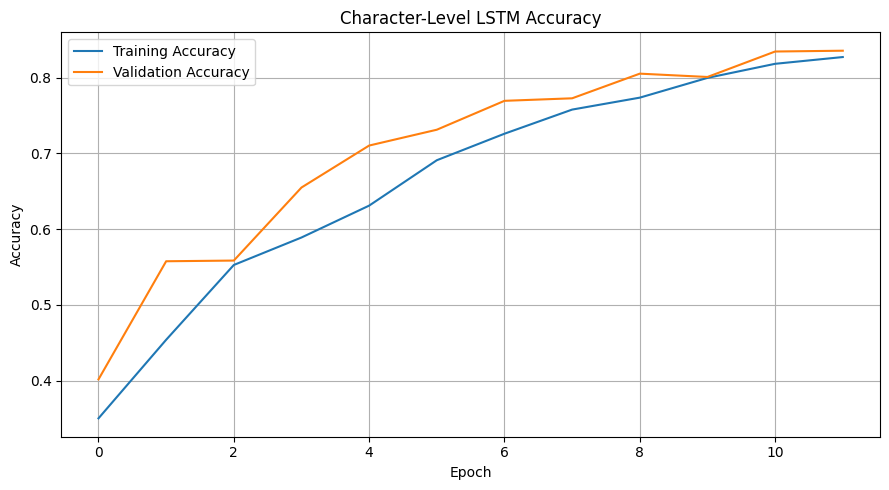

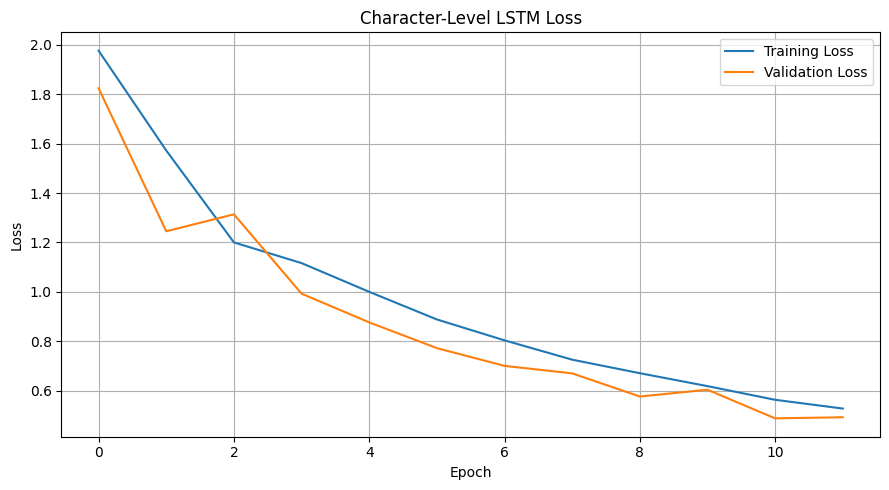

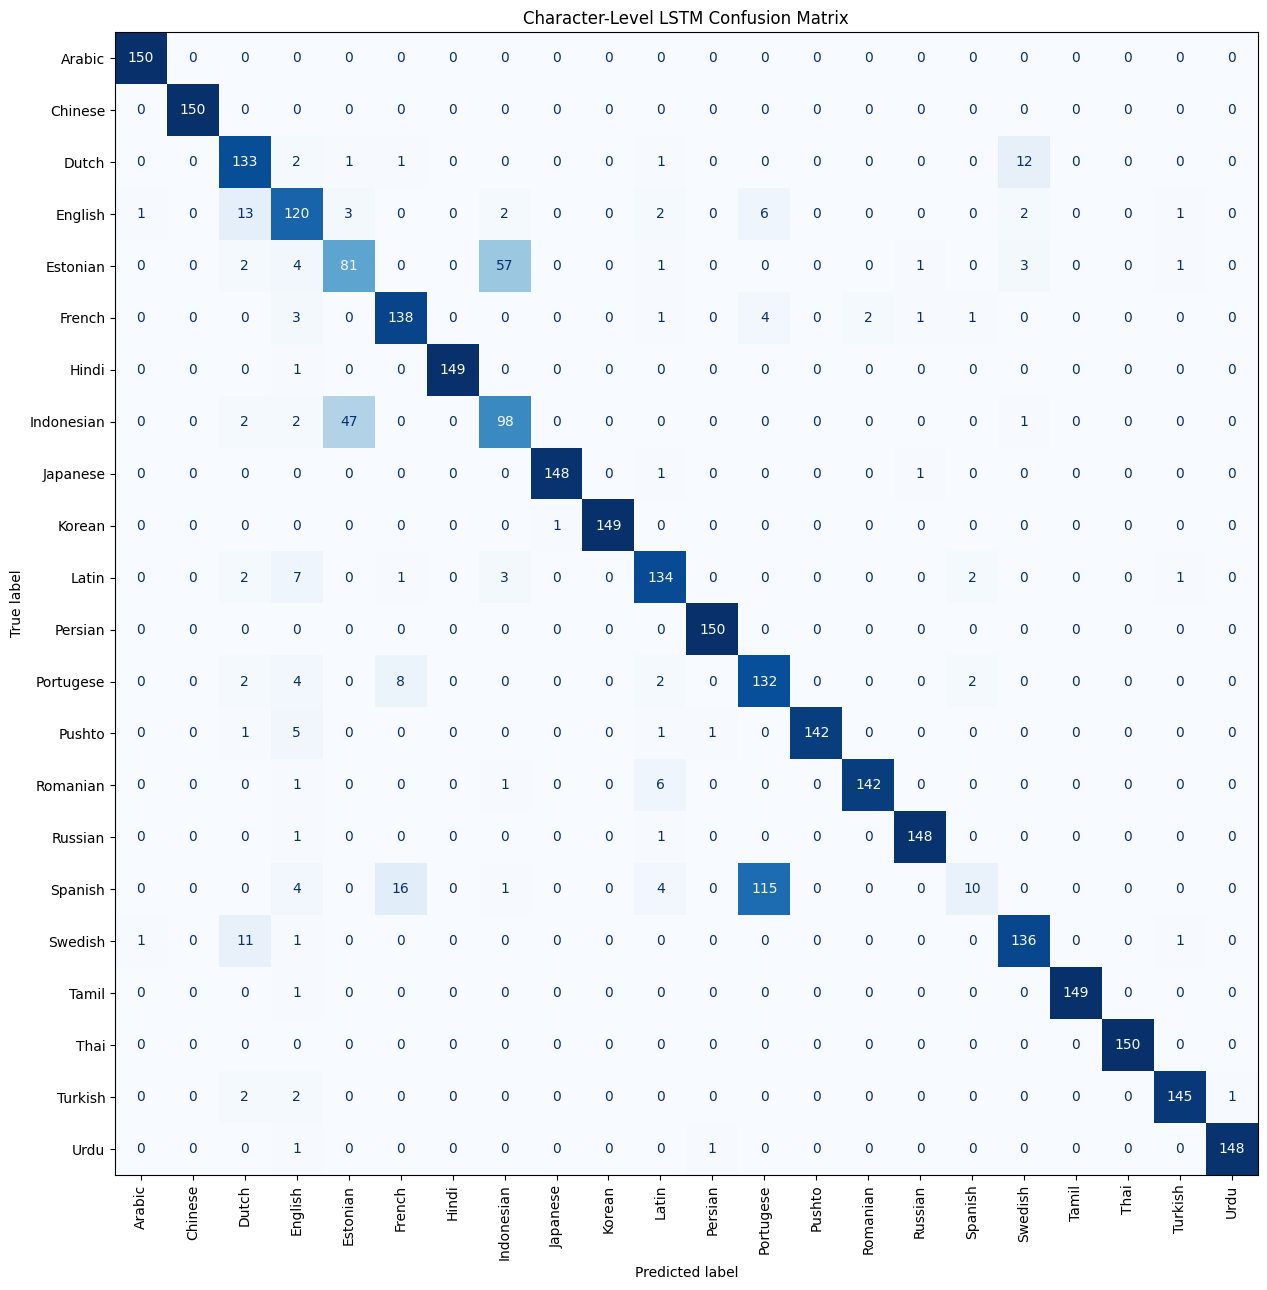


PROJECT COMPLETED
Model saved to: /kaggle/working/language_identification_char_lstm.keras
Preprocessing saved to: /kaggle/working/language_identification_preprocessing.pkl
Final test accuracy: 87.94%
Short excerpt accuracy: 79.85%

Download the two saved files from /kaggle/working.


In [10]:

# ==============================================================
# COMPLETE LANGUAGE IDENTIFICATION PROJECT
# Character-Level LSTM + Short-Text Augmentation
# Run this entire script in ONE new Kaggle notebook cell.
# ==============================================================

# CELL 1: IMPORT LIBRARIES
import os
import re
import pickle
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("=" * 65)
print("LANGUAGE IDENTIFICATION USING CHARACTER-LEVEL LSTM")
print("=" * 65)
print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))


# CELL 2: FIND AND LOAD DATASET
# Automatically searches Kaggle input folders.
CSV_PATH = None  # Set a full path here only if automatic search fails.

if CSV_PATH is None:
    search_dirs = [
        Path("/kaggle/input"),
        Path("/kaggle/working"),
        Path.cwd()
    ]

    all_csv_files = []

    for directory in search_dirs:
        if directory.exists():
            for path in directory.rglob("*.csv"):
                if path not in all_csv_files:
                    all_csv_files.append(path)

    matches = [
        path for path in all_csv_files
        if re.sub(r"[^a-z0-9]", "", path.stem.lower())
        == "languagedetection"
    ]

    if matches:
        CSV_PATH = str(matches[0])
    elif len(all_csv_files) == 1:
        CSV_PATH = str(all_csv_files[0])
    else:
        print("CSV files discovered:")
        for path in all_csv_files[:30]:
            print(path)

        raise FileNotFoundError(
            "Could not identify Language Detection.csv. "
            "Attach the dataset through Kaggle Add Input, "
            "or enter its full path in CSV_PATH."
        )

print("\nDataset path:", CSV_PATH)

df = pd.read_csv(CSV_PATH)
df.columns = [str(c).strip() for c in df.columns]

column_lookup = {
    str(column).strip().lower(): column
    for column in df.columns
}

if "text" not in column_lookup or "language" not in column_lookup:
    raise ValueError(
        "The CSV must contain Text and language columns. "
        f"Found columns: {df.columns.tolist()}"
    )

df = df[
    [column_lookup["text"], column_lookup["language"]]
].copy()

df.columns = ["Text", "language"]

df = df.dropna(subset=["Text", "language"]).copy()
df["Text"] = df["Text"].astype(str).str.strip()
df["language"] = df["language"].astype(str).str.strip()

df = df[
    (df["Text"] != "") &
    (df["language"] != "")
].reset_index(drop=True)

print("\nInitial cleaned shape:", df.shape)
print("Original language count:", df["language"].nunique())
print("\nExample records:")
print(df.head())


# CELL 3: BALANCE THE DATASET
MAX_SAMPLES_PER_LANGUAGE = 2000

groups = []

for language, group in df.groupby("language", sort=True):
    n = min(len(group), MAX_SAMPLES_PER_LANGUAGE)

    groups.append(
        group.sample(n=n, random_state=SEED)
    )

df = pd.concat(groups, ignore_index=True)
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)

print("\nBalanced dataset shape:", df.shape)
print("\nSamples per language:")
print(df["language"].value_counts().sort_index())


# CELL 4: LABEL ENCODING AND DATA SPLITTING
label_encoder = LabelEncoder()

X = df["Text"].to_numpy(dtype=object)
y = label_encoder.fit_transform(df["language"].to_numpy())

num_classes = len(label_encoder.classes_)

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("\nSupported languages:")
print(list(label_encoder.classes_))
print("\nNumber of classes:", num_classes)
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))


# CELL 5: BUILD A CHARACTER VOCABULARY
# Unlike word tokenization, this retains individual characters,
# punctuation, spaces, and different writing systems.

PAD_ID = 0
UNK_ID = 1

def normalize_text(text):
    return str(text).lower()

# Fit vocabulary using training texts only.
training_characters = set()

for text in X_train:
    training_characters.update(normalize_text(text))

char2idx = {
    character: index
    for index, character in enumerate(
        sorted(training_characters),
        start=2
    )
}

char_vocab_size = len(char2idx) + 2

train_lengths = np.array([
    len(normalize_text(text)) for text in X_train
])

MAX_CHAR_LEN = int(
    np.clip(np.percentile(train_lengths, 95), 120, 250)
)

print("\nCharacter vocabulary size:", char_vocab_size)
print("Maximum sequence length:", MAX_CHAR_LEN)

print(
    "Training texts exceeding sequence length:",
    f"{np.mean(train_lengths > MAX_CHAR_LEN) * 100:.2f}%"
)


# CELL 6: ENCODE TEXT AND CREATE SHORT EXCERPTS
def encode_texts(texts):
    """Encode characters and post-pad/truncate sequences."""
    result = np.zeros(
        (len(texts), MAX_CHAR_LEN),
        dtype=np.int32
    )

    for row, text in enumerate(texts):
        normalized = normalize_text(text)[:MAX_CHAR_LEN]

        ids = [
            char2idx.get(character, UNK_ID)
            for character in normalized
        ]

        if ids:
            result[row, :len(ids)] = ids

    return result


def make_random_excerpt(text, rng, min_chars=10, max_chars=120):
    """Return a reproducible random contiguous excerpt."""
    text = str(text)
    length = len(text)

    if length <= min_chars:
        return text

    upper = min(max_chars, length)
    excerpt_length = int(
        rng.integers(min_chars, upper + 1)
    )

    start = int(
        rng.integers(0, length - excerpt_length + 1)
    )

    return text[start:start + excerpt_length]


train_rng = np.random.default_rng(42)
val_rng = np.random.default_rng(43)
test_rng = np.random.default_rng(44)

X_train_excerpt = np.array([
    make_random_excerpt(text, train_rng)
    for text in X_train
], dtype=object)

X_val_excerpt = np.array([
    make_random_excerpt(text, val_rng)
    for text in X_val
], dtype=object)

X_test_excerpt = np.array([
    make_random_excerpt(text, test_rng)
    for text in X_test
], dtype=object)

# Augment training examples with excerpts from the same
# training examples. Labels remain unchanged.
X_train_aug = np.concatenate([
    X_train,
    X_train_excerpt
])

y_train_aug = np.concatenate([
    y_train,
    y_train
])

# Include short excerpts when monitoring validation loss.
X_val_aug = np.concatenate([
    X_val,
    X_val_excerpt
])

y_val_aug = np.concatenate([
    y_val,
    y_val
])

X_train_pad = encode_texts(X_train_aug)
X_val_pad = encode_texts(X_val_aug)

# Keep full held-out samples and excerpts separate.
X_test_pad = encode_texts(X_test)
X_test_excerpt_pad = encode_texts(X_test_excerpt)

print("\nTraining array:", X_train_pad.shape)
print("Validation array:", X_val_pad.shape)
print("Full test array:", X_test_pad.shape)
print("Test excerpt array:", X_test_excerpt_pad.shape)


# CELL 7: BUILD THE CHARACTER-LEVEL LSTM
char_model = Sequential([
    Embedding(
        input_dim=char_vocab_size,
        output_dim=32,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.3),
    Dense(num_classes, activation="softmax")
])

char_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

char_model.summary()


# CELL 8: TRAIN THE MODEL
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=1e-5,
    verbose=1
)

print("\nStarting training...")

history = char_model.fit(
    X_train_pad,
    y_train_aug,
    validation_data=(X_val_pad, y_val_aug),
    epochs=12,
    batch_size=128,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

print("\nTraining completed.")


# CELL 9: EVALUATE ON FULL HELD-OUT TEST TEXTS
test_loss, test_accuracy = char_model.evaluate(
    X_test_pad,
    y_test,
    verbose=0
)

test_probabilities = char_model.predict(
    X_test_pad,
    batch_size=256,
    verbose=0
)

test_predictions = np.argmax(test_probabilities, axis=1)

print("\n" + "=" * 50)
print("FULL TEST DATASET RESULTS")
print("=" * 50)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

print(
    "Macro precision:",
    f"{precision_score(y_test, test_predictions, average='macro', zero_division=0):.4f}"
)

print(
    "Macro recall:",
    f"{recall_score(y_test, test_predictions, average='macro', zero_division=0):.4f}"
)

print(
    "Macro F1-score:",
    f"{f1_score(y_test, test_predictions, average='macro', zero_division=0):.4f}"
)

print("\nClassification report:")
print(classification_report(
    y_test,
    test_predictions,
    labels=np.arange(num_classes),
    target_names=label_encoder.classes_,
    zero_division=0,
    digits=4
))


# CELL 10: EVALUATE SHORT EXCERPTS SEPARATELY
excerpt_probabilities = char_model.predict(
    X_test_excerpt_pad,
    batch_size=256,
    verbose=0
)

excerpt_predictions = np.argmax(
    excerpt_probabilities,
    axis=1
)

print("\n" + "=" * 50)
print("SHORT EXCERPT RESULTS")
print("=" * 50)

print(
    "Excerpt accuracy:",
    f"{accuracy_score(y_test, excerpt_predictions):.2%}"
)

print(
    "Excerpt macro F1-score:",
    f"{f1_score(y_test, excerpt_predictions, average='macro', zero_division=0):.4f}"
)


# CELL 11: TEST MANUALLY WRITTEN SENTENCES
sample_texts = [
    "Hello, how are you?",
    "Bonjour, comment allez-vous ?",
    "Hola, ¿cómo estás?",
    "Guten Morgen, wie geht es dir?",
    "தமிழ் என் தாய்மொழி",
    "邓斯特在年的电影中首度献唱"
]

sample_pad = encode_texts(sample_texts)

sample_probabilities = char_model.predict(
    sample_pad,
    verbose=0
)

print("\n" + "=" * 50)
print("CUSTOM INPUT PREDICTIONS")
print("=" * 50)

for text, probabilities in zip(sample_texts, sample_probabilities):
    top_indices = np.argsort(probabilities)[-3:][::-1]

    print("\nInput:", text)
    print("Top three predictions:")

    for idx in top_indices:
        language = label_encoder.inverse_transform([idx])[0]
        confidence = probabilities[idx] * 100

        print(f"  {language}: {confidence:.2f}%")

print(
    "\nNote: German is not a supported class unless German "
    "training examples are added to the dataset."
)


# CELL 12: PLOT TRAINING ACCURACY
plt.figure(figsize=(9, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Character-Level LSTM Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# CELL 13: PLOT TRAINING LOSS
plt.figure(figsize=(9, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Character-Level LSTM Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# CELL 14: CONFUSION MATRIX
cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=np.arange(num_classes)
)

fig, ax = plt.subplots(figsize=(15, 13))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
).plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

plt.title("Character-Level LSTM Confusion Matrix")
plt.tight_layout()
plt.show()


# CELL 15: SAVE MODEL AND PREPROCESSING
OUTPUT_DIR = Path("/kaggle/working")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

model_path = OUTPUT_DIR / "language_identification_char_lstm.keras"
preprocessing_path = OUTPUT_DIR / "language_identification_preprocessing.pkl"

char_model.save(str(model_path))

with open(preprocessing_path, "wb") as file:
    pickle.dump({
        "char2idx": char2idx,
        "label_encoder": label_encoder,
        "max_char_len": MAX_CHAR_LEN,
        "pad_id": PAD_ID,
        "unknown_id": UNK_ID
    }, file)

print("\n" + "=" * 50)
print("PROJECT COMPLETED")
print("=" * 50)
print("Model saved to:", model_path)
print("Preprocessing saved to:", preprocessing_path)
print("Final test accuracy:", f"{test_accuracy:.2%}")
print(
    "Short excerpt accuracy:",
    f"{accuracy_score(y_test, excerpt_predictions):.2%}"
)
print("\nDownload the two saved files from /kaggle/working.")


In [11]:

# ============================================================
# IMPROVED MODEL: UP TO 50 EPOCHS + 500-CHARACTER SEQUENCES
# Run this in ONE NEW CELL after your previous notebook cell.
# ============================================================

import numpy as np
import tensorflow as tf
from pathlib import Path
import pickle

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# 1. Verify the previous notebook execution is available.
required_variables = [
    "char2idx",
    "char_vocab_size",
    "X_train_aug",
    "y_train_aug",
    "X_val_aug",
    "y_val_aug",
    "X_test",
    "X_test_excerpt",
    "y_test",
    "num_classes",
    "label_encoder"
]

missing = [
    variable for variable in required_variables
    if variable not in globals()
]

if missing:
    raise NameError(
        f"Missing variables: {missing}. "
        "Run your original complete project cell first."
    )

# 2. Increase sequence length.
MAX_CHAR_LEN_V2 = 500

train_lengths = np.array([len(str(text)) for text in X_train_aug])

print("New maximum sequence length:", MAX_CHAR_LEN_V2)
print(
    "Training texts exceeding 500 characters:",
    f"{np.mean(train_lengths > MAX_CHAR_LEN_V2) * 100:.2f}%"
)

# 3. Encode text using the existing character vocabulary.
def encode_texts_v2(texts):
    result = np.zeros(
        (len(texts), MAX_CHAR_LEN_V2),
        dtype=np.int32
    )

    for row, text in enumerate(texts):
        text = str(text).lower()[:MAX_CHAR_LEN_V2]

        ids = [
            char2idx.get(character, 1)
            for character in text
        ]

        if ids:
            result[row, :len(ids)] = ids

    return result


X_train_v2 = encode_texts_v2(X_train_aug)
X_val_v2 = encode_texts_v2(X_val_aug)
X_test_v2 = encode_texts_v2(X_test)
X_test_excerpt_v2 = encode_texts_v2(X_test_excerpt)

print("Training shape:", X_train_v2.shape)
print("Validation shape:", X_val_v2.shape)
print("Test shape:", X_test_v2.shape)

# 4. Build a fresh model.
char_model_v2 = Sequential([
    Input(shape=(MAX_CHAR_LEN_V2,), dtype="int32"),
    Embedding(
        input_dim=char_vocab_size,
        output_dim=32,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.3),
    Dense(num_classes, activation="softmax")
])

char_model_v2.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

char_model_v2.summary()

# 5. Train for up to 50 epochs.
early_stop_v2 = EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_v2 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-5,
    verbose=1
)

history_v2 = char_model_v2.fit(
    X_train_v2,
    y_train_aug,
    validation_data=(X_val_v2, y_val_aug),
    epochs=50,
    batch_size=128,
    callbacks=[reduce_lr_v2, early_stop_v2],
    verbose=1
)

print("\nTraining finished.")
print("Best validation accuracy:",
      f"{max(history_v2.history['val_accuracy']):.2%}")
print("Epochs completed:", len(history_v2.history["loss"]))

# 6. Evaluate on the same held-out test set.
test_loss_v2, test_accuracy_v2 = char_model_v2.evaluate(
    X_test_v2,
    y_test,
    verbose=0
)

test_probabilities_v2 = char_model_v2.predict(
    X_test_v2,
    batch_size=256,
    verbose=0
)

test_predictions_v2 = np.argmax(test_probabilities_v2, axis=1)

print("\n========== FULL TEST RESULTS ==========")
print(f"Test loss: {test_loss_v2:.4f}")
print(f"Test accuracy: {test_accuracy_v2:.2%}")

print(
    "Macro precision:",
    f"{precision_score(y_test, test_predictions_v2, average='macro', zero_division=0):.4f}"
)
print(
    "Macro recall:",
    f"{recall_score(y_test, test_predictions_v2, average='macro', zero_division=0):.4f}"
)
print(
    "Macro F1-score:",
    f"{f1_score(y_test, test_predictions_v2, average='macro', zero_division=0):.4f}"
)

print("\nClassification report:")
print(classification_report(
    y_test,
    test_predictions_v2,
    labels=np.arange(num_classes),
    target_names=label_encoder.classes_,
    zero_division=0,
    digits=4
))

# 7. Evaluate short excerpts separately.
excerpt_probabilities_v2 = char_model_v2.predict(
    X_test_excerpt_v2,
    batch_size=256,
    verbose=0
)

excerpt_predictions_v2 = np.argmax(
    excerpt_probabilities_v2,
    axis=1
)

print("\n========== SHORT EXCERPT RESULTS ==========")
print(
    "Excerpt accuracy:",
    f"{accuracy_score(y_test, excerpt_predictions_v2):.2%}"
)
print(
    "Excerpt macro F1-score:",
    f"{f1_score(y_test, excerpt_predictions_v2, average='macro', zero_division=0):.4f}"
)

# 8. Test the original manual sentences.
sample_texts = [
    "Hello, how are you?",
    "Bonjour, comment allez-vous ?",
    "Hola, ¿cómo estás?",
    "Guten Morgen, wie geht es dir?",
    "தமிழ் என் தாய்மொழி",
    "邓斯特在年的电影中首度献唱"
]

sample_probabilities_v2 = char_model_v2.predict(
    encode_texts_v2(sample_texts),
    verbose=0
)

print("\n========== CUSTOM PREDICTIONS ==========")

for text, probabilities in zip(sample_texts, sample_probabilities_v2):
    top_indices = np.argsort(probabilities)[-3:][::-1]

    print("\nInput:", text)

    for index in top_indices:
        language = label_encoder.inverse_transform([index])[0]
        confidence = probabilities[index] * 100
        print(f"  {language}: {confidence:.2f}%")

# 9. Save the improved model and preprocessing.
output_dir = Path("/kaggle/working")
output_dir.mkdir(parents=True, exist_ok=True)

model_path_v2 = output_dir / "language_identification_lstm_v2.keras"
preprocessing_path_v2 = output_dir / "language_identification_preprocessing_v2.pkl"

char_model_v2.save(str(model_path_v2))

with open(preprocessing_path_v2, "wb") as file:
    pickle.dump({
        "char2idx": char2idx,
        "label_encoder": label_encoder,
        "max_char_len": MAX_CHAR_LEN_V2,
        "unknown_id": 1,
        "padding_id": 0
    }, file)

print("\nSaved model:", model_path_v2)
print("Saved preprocessing:", preprocessing_path_v2)


New maximum sequence length: 500
Training texts exceeding 500 characters: 9.58%
Training shape: (30798, 500)
Validation shape: (6600, 500)
Test shape: (3300, 500)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 500, 32)        │       212,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 22)             │         1,430 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 238,966 (933.46 KB)

 Trainable params: 238,966 (933.46 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
241/241 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.3406 - loss: 2.0261 - val_accuracy: 0.5323 - val_loss: 1.4032 - learning_rate: 0.0010
Epoch 2/50
241/241 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.5686 - loss: 1.2454 - val_accuracy: 0.6491 - val_loss: 1.0345 - learning_rate: 0.0010
Epoch 3/50
241/241 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.6103 - loss: 1.1493 - val_accuracy: 0.6638 - val_loss: 0.9756 - learning_rate: 0.0010
Epoch 4/50
241/241 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.6589 - loss: 0.9756 - val_accuracy: 0.6873 - val_loss: 0.8694 - learning_rate: 0.0010
Epoch 5/50
241/241 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.6996 - loss: 0.8110 - val_accuracy: 0.7312 - val_loss: 0.7314 - learning_rate: 0.0010
Epoch 6/50
241/241 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.7286 - loss: 0.7570 - val_accuracy: 0.7411 - val_loss: 0.7315 - learning_rate: 0.0010
Epoch 7/50
241/241 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.7452 - loss: 0.

In [12]:

# ============================================================
# TEST THE IMPROVED CHARACTER-LEVEL LSTM
# Uses char_model_v2 trained in the previous cell.
# ============================================================

import numpy as np

def predict_language(text, top_k=3):
    if not isinstance(text, str) or not text.strip():
        print("Please enter a non-empty text.")
        return

    # Convert characters into integer IDs.
    text = text.lower()[:MAX_CHAR_LEN_V2]

    sequence = [
        char2idx.get(character, 1)
        for character in text
    ]

    # Pad the input.
    padded = np.zeros(
        (1, MAX_CHAR_LEN_V2),
        dtype=np.int32
    )

    if sequence:
        padded[0, :len(sequence)] = sequence

    # Predict probabilities.
    probabilities = char_model_v2.predict(
        padded,
        verbose=0
    )[0]

    top_indices = np.argsort(probabilities)[::-1][:top_k]

    print("\nInput text:", text)
    print("\nTop predictions:")

    for rank, index in enumerate(top_indices, start=1):
        language = label_encoder.inverse_transform([index])[0]
        confidence = probabilities[index] * 100

        print(
            f"{rank}. {language}: {confidence:.2f}%"
        )

    predicted_index = int(np.argmax(probabilities))
    predicted_language = label_encoder.inverse_transform(
        [predicted_index]
    )[0]

    print("\nPredicted language:", predicted_language)
    print(
        "Top prediction probability:",
        f"{probabilities[predicted_index] * 100:.2f}%"
    )


# Test different languages.
test_texts = [
    "Hello, how are you?",
    "Bonjour, comment allez-vous ?",
    "Hola, ¿cómo estás?",
    "தமிழ் என் தாய்மொழி",
    "邓斯特在年的电影中首度献唱",
    "Selamat pagi, apa kabar?"
]

for sentence in test_texts:
    predict_language(sentence)
    print("-" * 50)



Input text: hello, how are you?

Top predictions:
1. English: 45.02%
2. Dutch: 11.27%
3. Portugese: 8.92%

Predicted language: English
Top prediction probability: 45.02%
--------------------------------------------------

Input text: bonjour, comment allez-vous ?

Top predictions:
1. Dutch: 34.48%
2. French: 18.98%
3. Spanish: 14.75%

Predicted language: Dutch
Top prediction probability: 34.48%
--------------------------------------------------

Input text: hola, ¿cómo estás?

Top predictions:
1. Portugese: 58.78%
2. Spanish: 39.33%
3. Pushto: 0.72%

Predicted language: Portugese
Top prediction probability: 58.78%
--------------------------------------------------

Input text: தமிழ் என் தாய்மொழி

Top predictions:
1. Tamil: 99.94%
2. Swedish: 0.02%
3. Thai: 0.02%

Predicted language: Tamil
Top prediction probability: 99.94%
--------------------------------------------------

Input text: 邓斯特在年的电影中首度献唱

Top predictions:
1. Chinese: 99.76%
2. Japanese: 0.07%
3. Dutch: 0.06%

Predicted lan

In [13]:

my_text = "I am learning artificial intelligence."

predict_language(my_text, top_k=5)



Input text: i am learning artificial intelligence.

Top predictions:
1. Latin: 70.97%
2. Romanian: 11.53%
3. French: 4.29%
4. English: 3.19%
5. Portugese: 2.25%

Predicted language: Latin
Top prediction probability: 70.97%


In [14]:

# Character n-gram TF-IDF + Linear SVM baseline

import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

svm_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            analyzer="char",
            ngram_range=(1, 5),
            min_df=2,
            max_features=300000,
            sublinear_tf=True,
            dtype=np.float32
        )
    ),
    (
        "classifier",
        LinearSVC(C=1.0)
    )
])

print("Training character n-gram SVM...")

svm_model.fit(X_train, y_train)

# Evaluate on the same held-out dataset.
svm_predictions = svm_model.predict(X_test)

print("\n========== SVM TEST RESULTS ==========")
print(
    f"Accuracy: {accuracy_score(y_test, svm_predictions):.2%}"
)
print(
    "Macro precision:",
    f"{precision_score(y_test, svm_predictions, average='macro', zero_division=0):.4f}"
)
print(
    "Macro recall:",
    f"{recall_score(y_test, svm_predictions, average='macro', zero_division=0):.4f}"
)
print(
    "Macro F1:",
    f"{f1_score(y_test, svm_predictions, average='macro', zero_division=0):.4f}"
)

print("\nClassification report:")
print(classification_report(
    y_test,
    svm_predictions,
    labels=np.arange(num_classes),
    target_names=label_encoder.classes_,
    zero_division=0,
    digits=4
))

# Test short, manually written sentences.
samples = [
    "I am learning artificial intelligence.",
    "Hello, how are you?",
    "Bonjour, comment allez-vous ?",
    "Hola, ¿cómo estás?",
    "தமிழ் என் தாய்மொழி",
    "邓斯特在年的电影中首度献唱"
]

sample_predictions = svm_model.predict(samples)

print("\n========== CUSTOM SENTENCE TEST ==========")

for text, pred in zip(samples, sample_predictions):
    language = label_encoder.inverse_transform([pred])[0]
    print("Text:", text)
    print("Predicted language:", language)
    print("-" * 40)


Training character n-gram SVM...

========== SVM TEST RESULTS ==========
Accuracy: 99.03%
Macro precision: 0.9911
Macro recall: 0.9903
Macro F1: 0.9905

Classification report:
              precision    recall  f1-score   support

      Arabic     1.0000    1.0000    1.0000       150
     Chinese     1.0000    0.9933    0.9967       150
       Dutch     0.9934    1.0000    0.9967       150
     English     0.8772    1.0000    0.9346       150
    Estonian     1.0000    0.9667    0.9831       150
      French     1.0000    0.9800    0.9899       150
       Hindi     1.0000    1.0000    1.0000       150
  Indonesian     1.0000    0.9933    0.9967       150
    Japanese     1.0000    0.9933    0.9967       150
      Korean     1.0000    1.0000    1.0000       150
       Latin     0.9600    0.9600    0.9600       150
     Persian     1.0000    1.0000    1.0000       150
   Portugese     0.9934    1.0000    0.9967       150
      Pushto     1.0000    0.9600    0.9796       150
    Romanian 

In [15]:

# ============================================================
# IMPROVE SVM FOR SHORT-TEXT LANGUAGE IDENTIFICATION
# Uses existing X_train, y_train, X_test, y_test.
# Does not modify your existing svm_model.
# ============================================================

import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score

rng = np.random.default_rng(2026)


# 1. Generate random fragments from training documents only.
def make_fragment(text, min_chars=15, max_chars=100):
    text = str(text)

    if len(text) <= min_chars:
        return text

    upper = min(max_chars, len(text))
    length = int(rng.integers(min_chars, upper + 1))
    start = int(rng.integers(0, len(text) - length + 1))

    return text[start:start + length]


# Create two fragments per training document.
train_fragments_1 = [
    make_fragment(text, 15, 60)
    for text in X_train
]

train_fragments_2 = [
    make_fragment(text, 30, 120)
    for text in X_train
]

# Combine original texts and fragments.
X_train_svm_aug = np.concatenate([
    X_train,
    np.array(train_fragments_1, dtype=object),
    np.array(train_fragments_2, dtype=object)
])

y_train_svm_aug = np.concatenate([
    y_train,
    y_train,
    y_train
])

print("Original training texts:", len(X_train))
print("Augmented training texts:", len(X_train_svm_aug))


# 2. Build the new SVM pipeline.
svm_model_aug = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            analyzer="char",
            ngram_range=(1, 5),
            min_df=2,
            max_features=300000,
            sublinear_tf=True,
            dtype=np.float32
        )
    ),
    (
        "classifier",
        LinearSVC(C=1.0)
    )
])


# 3. Train the augmented model.
print("\nTraining the augmented SVM...")

svm_model_aug.fit(
    X_train_svm_aug,
    y_train_svm_aug
)

print("Training complete.")


# 4. Evaluate on full held-out test documents.
full_predictions = svm_model_aug.predict(X_test)

print("\n========== FULL TEST DOCUMENTS ==========")

print(
    f"Accuracy: {accuracy_score(y_test, full_predictions):.2%}"
)

print(
    "Macro F1:",
    f"{f1_score(y_test, full_predictions, average='macro'):.4f}"
)


# 5. Generate unseen fragments from held-out test documents.
# No X_test fragments were used to train this model.
test_rng = np.random.default_rng(2027)

def make_test_fragment(text, rng, min_chars=15, max_chars=100):
    text = str(text)

    if len(text) <= min_chars:
        return text

    upper = min(max_chars, len(text))
    length = int(rng.integers(min_chars, upper + 1))
    start = int(rng.integers(0, len(text) - length + 1))

    return text[start:start + length]


X_test_short = np.array([
    make_test_fragment(text, test_rng)
    for text in X_test
], dtype=object)

short_predictions = svm_model_aug.predict(X_test_short)

print("\n========== SHORT TEST FRAGMENTS ==========")

print(
    f"Accuracy: {accuracy_score(y_test, short_predictions):.2%}"
)

print(
    "Macro F1:",
    f"{f1_score(y_test, short_predictions, average='macro'):.4f}"
)


# 6. Test manually written sentences.
sample_texts = [
    "I am learning artificial intelligence.",
    "Hello, how are you?",
    "Bonjour, comment allez-vous ?",
    "Hola, ¿cómo estás?",
    "தமிழ் என் தாய்மொழி",
    "邓斯特在年的电影中首度献唱"
]

custom_predictions = svm_model_aug.predict(sample_texts)

print("\n========== CUSTOM SENTENCE RESULTS ==========")

for text, pred in zip(sample_texts, custom_predictions):
    language = label_encoder.inverse_transform([pred])[0]

    print("Input:", text)
    print("Predicted language:", language)
    print("-" * 45)


# 7. Inspect the top three decision scores for the English sentence.
# LinearSVC scores are margins, NOT calibrated probabilities.
text = "I am learning artificial intelligence."
scores = svm_model_aug.decision_function([text])[0]

top_indices = np.argsort(scores)[::-1][:3]

print("\nTop decision scores for the English sentence:")

for index in top_indices:
    language = label_encoder.inverse_transform([int(index)])[0]
    print(f"{language}: margin {scores[index]:.4f}")


Original training texts: 15399
Augmented training texts: 46197

Training the augmented SVM...
Training complete.

========== FULL TEST DOCUMENTS ==========
Accuracy: 99.03%
Macro F1: 0.9904

========== SHORT TEST FRAGMENTS ==========
Accuracy: 97.33%
Macro F1: 0.9736

========== CUSTOM SENTENCE RESULTS ==========
Input: I am learning artificial intelligence.
Predicted language: Hindi
---------------------------------------------
Input: Hello, how are you?
Predicted language: English
---------------------------------------------
Input: Bonjour, comment allez-vous ?
Predicted language: French
---------------------------------------------
Input: Hola, ¿cómo estás?
Predicted language: Spanish
---------------------------------------------
Input: தமிழ் என் தாய்மொழி
Predicted language: Tamil
---------------------------------------------
Input: 邓斯特在年的电影中首度献唱
Predicted language: Chinese
---------------------------------------------

Top decision scores for the English sentence:
Hindi: margin -0

In [17]:
import numpy as np

from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score

combined_svm = Pipeline([
    ("features", FeatureUnion([
        ("character_ngrams", TfidfVectorizer(
            analyzer="char",
            ngram_range=(1, 5),
            min_df=2,
            max_features=300000,
            sublinear_tf=True,
            dtype=np.float32
        )),
        ("word_ngrams", TfidfVectorizer(
            analyzer="word",
            ngram_range=(1, 2),
            token_pattern=r"(?u)\b\w+\b",
            min_df=2,
            max_features=200000,
            sublinear_tf=True,
            dtype=np.float32
        ))
    ])),
    ("classifier", LinearSVC(C=1.0))
])

print("Training combined character + word SVM...")

combined_svm.fit(X_train_svm_aug, y_train_svm_aug)

# Evaluate on the same held-out test documents.
full_pred = combined_svm.predict(X_test)

print("\nFull-test accuracy:",
      f"{accuracy_score(y_test, full_pred):.2%}")
print("Full-test macro F1:",
      f"{f1_score(y_test, full_pred, average='macro'):.4f}")

# Evaluate short fragments from the held-out test documents.
short_pred = combined_svm.predict(X_test_short)

print("\nShort-fragment accuracy:",
      f"{accuracy_score(y_test, short_pred):.2%}")
print("Short-fragment macro F1:",
      f"{f1_score(y_test, short_pred, average='macro'):.4f}")

# Retest the problematic English sentence and other samples.
samples = [
    "Hello, how are you?",
    "Bonjour, comment allez-vous ?",
    "Hola, ¿cómo estás?",
    "தமிழ் என் தாய்மொழி",
    "邓斯特在年的电影中首度献唱"
]

predictions = combined_svm.predict(samples)

print("\nCUSTOM SENTENCE TEST")

for text, pred in zip(samples, predictions):
    language = label_encoder.inverse_transform([pred])[0]
    print(f"{text}\nPrediction: {language}\n")

Training combined character + word SVM...

Full-test accuracy: 99.12%
Full-test macro F1: 0.9914

Short-fragment accuracy: 97.39%
Short-fragment macro F1: 0.9742

CUSTOM SENTENCE TEST
Hello, how are you?
Prediction: English

Bonjour, comment allez-vous ?
Prediction: French

Hola, ¿cómo estás?
Prediction: Spanish

தமிழ் என் தாய்மொழி
Prediction: Tamil

邓斯特在年的电影中首度献唱
Prediction: Chinese

